# Calcusol · R3 · Física y finanzas — paso a paso

**Pregunta que responde este notebook:** si una familia pone paneles solares, *¿cuánto ahorra y en cuántos años recupera la inversión?*
…y **¿cuánto cambia esa respuesta si usamos el sol medido (IDEAM), el de NASA o el corregido por nuestro modelo?**

Corre las celdas **en orden, de arriba hacia abajo** (botón ▶ o `Shift + Enter`). Lee el texto antes de cada una.

**Archivos que necesitas** (súbelos en la carpeta 📁 de la izquierda de Colab):
1. `calcusol_r3.py` — el código (las "recetas")
2. `config_r3.yaml` — la ficha con todos los números (tarifas, costos…)
3. `evaluacion_lightgbm_final.xlsx` — la evaluación FINAL de Manuela (R2): los 3 casos y, hora por hora, el sol del IDEAM, de NASA y del modelo en cada caso
4. *(solo para el Paso 11, un lugar nuevo)* `modelo_lgbm.joblib` de Juan Diego (R1) y `gold_v1_unico.parquet` de Felipe (R5)

**Dónde cambias los valores (estrato, consumo, kWp, costo, coordenadas…):**
- **Paso 10b**: tus valores en los 3 lugares de Manuela.
- **Paso 11.2**: cualquier lugar de Colombia (coordenadas) con tus valores.
- **Paso 11.3**: ese mismo lugar en los 6 estratos y en varios tamaños.

*Versión final: 21 de noviembre de 2026 (evaluación final de R2).*

## Paso 0 · Instalar herramientas
`pvlib` es la calculadora de energía solar y `lightgbm` es la librería del modelo final de R1.

In [21]:
!pip install -q pvlib pyyaml lightgbm

## Paso 1 · Cargar la ficha de parámetros
Todos los números (tarifa, costo del panel, inclinación…) viven en `config_r3.yaml`, **nunca dentro del código** (así lo pide el plan). Aquí ves la ficha: la columna **Estado** dice `PRUEBA` si el número todavía no tiene fuente verificada.

In [22]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import calcusol_r3 as r3
pd.set_option('display.max_colwidth', 80); pd.set_option('display.width', 200)

cfg = r3.cargar_config('config_r3.yaml')
# Rutas de los archivos (cámbialas cuando lleguen los datos reales)
cfg['datos']['casos_r2']   = 'evaluacion_lightgbm_final.xlsx'   # Manuela (R2): casos + serie horaria
cfg['datos']['tabla_gold'] = 'gold_v1_unico.parquet'            # Felipe (R5): solo Paso 11
cfg['datos']['modelo']     = 'modelo_lgbm.joblib'               # Juan Diego (R1): solo Paso 11
cfg['datos']['predicciones_r2'] = None

r3.ficha_supuestos(cfg)

,Grupo,Parametro,Valor,Fuente,Estado
0,sistema,kWp,1.5,Decisión: tamaño que produce ~ lo que consume la casa en un año (157 kWh/mes...,DECISION
1,sistema,inclinacion_grados,10,Decisión del equipo D13,DECISION
2,sistema,azimut_grados,180,Decisión del equipo D13 (mirando al sur),DECISION
3,sistema,albedo,0.2,"NREL, PVWatts Version 5 Manual (Dobos, 2014): albedo fijo en 0.2 por defecto",OK
4,sistema,perdidas_sistema,0.14,"NREL, PVWatts Version 5 Manual (Dobos, 2014): pérdidas totales del sistema 1...",OK
5,sistema,eficiencia_inversor,0.96,NREL PVWatts API v8: eficiencia nominal del inversor 96 % por defecto. https...,OK
6,sistema,noct_c,45,Ficha técnica Jinko Tiger Neo JKM425-445N-54HL4R-B: NOCT 45 ± 2 °C,OK
7,sistema,coef_temp_potencia_por_c,-0.0029,Ficha técnica Jinko Tiger Neo JKM425-445N-54HL4R-B: coeficiente de temperatu...,OK
8,sistema,degradacion_primer_anio,0.01,Ficha técnica Jinko Tiger Neo 54HL4R-B: degradación primer año 1 %,OK
9,sistema,degradacion_anual,0.004,Ficha técnica Jinko Tiger Neo 54HL4R-B: 0.40 % anual durante 30 años,OK


### Paso 1b · Estilo de las gráficas
Una sola vez se define cómo se ven todas las gráficas del cuaderno:
- **Los mismos colores** en todo el cuaderno: IDEAM verde, NASA azul y modelo naranja. Además, cada fuente tiene su propio tipo de línea y marcador, para que se distinga aunque se imprima en blanco y negro.
- **Título, ejes y unidades del Sistema Internacional entre corchetes**, por ejemplo `Energía [kWh]`.
- **La leyenda va debajo de la gráfica**, para que nunca tape los datos.
- Cada gráfica se guarda también como imagen en la carpeta `figuras` (en alta resolución, lista para el informe).

In [23]:
import os, matplotlib as mpl
os.makedirs('figuras', exist_ok=True); os.makedirs('resultados', exist_ok=True)

COLORES = {'IDEAM': '#157A5B', 'NASA': '#2563C9', 'MODELO': '#C2560C'}
ETIQ    = {'IDEAM': 'IDEAM (medido)', 'NASA': 'NASA (sin corregir)', 'MODELO': 'Modelo (NASA corregida)'}
LINEA   = {'IDEAM': dict(ls='-', marker='o'), 'NASA': dict(ls='--', marker='s'), 'MODELO': dict(ls=':', marker='^')}
TRAMA   = {'IDEAM': None, 'NASA': '///', 'MODELO': '...'}
MESES   = ['Ene','Feb','Mar','Abr','May','Jun','Jul','Ago','Sep','Oct','Nov','Dic']
TINTA, GRIS, REJILLA = '#1F2937', '#6B7280', '#E5E7EB'

mpl.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 200, 'font.size': 10, 'font.family': 'DejaVu Sans',
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'axes.labelsize': 10, 'axes.labelcolor': TINTA, 'axes.edgecolor': GRIS,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': REJILLA, 'grid.linewidth': 0.8, 'xtick.color': GRIS, 'ytick.color': GRIS,
    'lines.linewidth': 2, 'lines.markersize': 5, 'legend.frameon': False, 'legend.fontsize': 9,
    'hatch.color': 'white', 'hatch.linewidth': 0.8})

def nombre_lugar(codigo):
    """'MOGOTES - AUT' -> 'Mogotes (Santander)'."""
    c = casos.set_index('CodigoEstacion').loc[codigo]
    return f"{c.NombreEstacion.replace('- AUT', '').strip().title()} ({c.Departamento.title()})"

def terminar(fig, archivo, ncol=3, handles=None, labels=None):
    """Pone la leyenda DEBAJO (sin tapar datos), ajusta márgenes, guarda la imagen y la muestra."""
    if handles is None:
        handles, labels = fig.axes[0].get_legend_handles_labels()
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, -0.02))
    fig.tight_layout(rect=(0, 0.08 if handles else 0, 1, 1))
    fig.savefig(f'figuras/{archivo}.png', bbox_inches='tight', facecolor='white')
    plt.show()

print('Estilo listo. Las figuras se guardan en la carpeta figuras/')

Estilo listo. Las figuras se guardan en la carpeta figuras/


## Paso 2 · Los 3 lugares (regla D16) y el sol de las 3 fuentes
Manuela evaluó el modelo en **112 sitios** con validación cruzada: cada sitio se evalúa con un modelo que **no lo vio** al entrenar. Con la regla D16 marcó **3 casos** en la columna `caso_sugerido`: el de **mayor** mejora, el **del medio** y el de **menor** mejora (es negativa: ahí el modelo empeora, y se reporta con honestidad).

Para esos 3 casos, su hoja `serie_horaria` trae **hora por hora** (en el año con más datos de cada sitio):
| Nombre | Columna en el motor | Qué es |
|---|---|---|
| **IDEAM** | `Valor` | Lo que midió el sensor en tierra → la **verdad** |
| **NASA** | `ALLSKY_SFC_SW_DWN` | Estimación del satélite, sin corregir |
| **MODELO** | `Prediccion` | NASA corregida por el LightGBM de un pliegue que **no vio** ese sitio |

**¿Por qué no usamos el `.joblib`?** Porque el modelo final aprendió con todos los sitios, incluidos estos 3: aquí acertaría "de más". El sol de Manuela es el resultado honesto para un lugar nuevo.


In [24]:
df = r3.cargar_serie_r2(cfg)
casos = r3.cargar_casos_r2(cfg, df)
mejora = r3.cargar_mejora_r2(cfg)
print('Filas:', len(df), '| Casos:', df.CodigoEstacion.nunique(), '| Años:', sorted(df.Fecha.dt.year.unique()))
casos[['Caso','NombreEstacion','Departamento','Mejora_pct']].round(1)

Filas: 11673 | Casos: 3 | Años: [np.int32(2008), np.int32(2011), np.int32(2013)]


,Caso,NombreEstacion,Departamento,Mejora_pct
0,Mayor mejora,ARAGÓN - AUT,Antioquia,77.9
1,Mediana,MOGOTES - AUT,Santander,16.3
2,Menor mejora,BATALLON ROOKE - AUT,Tolima,-228.6


## Paso 3 · ¿Cuánto se equivoca cada fuente en esas horas?
El error promedio por hora (MAE, en Wh/m²) de NASA y del MODELO frente al IDEAM, en el año de cada caso. Al lado, la mejora del **error mensual** que reporta Manuela para todo el sitio (es la cifra de negocio; incluye todos los años).

La cifra que resume al modelo **no** es la de estos 3 casos (la regla escoge a propósito el mejor, el del medio y el peor): es la de los 112 sitios, en la hoja `cv_resumen`.

In [25]:
mae = df.assign(NASA=(df.ALLSKY_SFC_SW_DWN - df.Valor).abs(), MODELO=(df.Prediccion - df.Valor).abs()).groupby('NombreEstacion')[['NASA','MODELO']].mean()
mae = mae.join(casos.set_index('NombreEstacion')[['Caso','Mejora_pct']].rename(columns={'Mejora_pct':'Mejora mensual R2 (%)'}))
display(mae.round(1))
cv = pd.read_excel(cfg['datos']['casos_r2'], sheet_name='cv_resumen', header=2)
cv[['esquema','examen','modelo','sitios','MAE_mes_NASA','MAE_mes_modelo','mejora_mes','IC95_mes_inf','IC95_mes_sup','pct_remuestreos_mes_a_favor']].head(2).round(3)

,NASA,MODELO,Caso,Mejora mensual R2 (%)
NombreEstacion,,,,
ARAGÓN - AUT,126.3,109.1,Mayor mejora,77.9
BATALLON ROOKE - AUT,113.8,128.3,Menor mejora,-228.6
MOGOTES - AUT,99.6,97.9,Mediana,16.3


,esquema,examen,modelo,sitios,MAE_mes_NASA,MAE_mes_modelo,mejora_mes,IC95_mes_inf,IC95_mes_sup,pct_remuestreos_mes_a_favor
0,Pliegues por Sitio,Espacial (todos los años),LightGBM (con ubicación),112,55.174,47.744,0.135,0.031,0.221,99.60
1,Pliegues por Sitio,Espacial (todos los años),LightGBM sin ubicación,112,55.174,48.179,0.127,0.036,0.202,99.55


## Paso 4 · Armar un "año típico" de 8,760 horas
Un año tiene 365 × 24 = **8,760 horas**. La tabla solo trae horas de día y tiene huecos, así que:
1. Para cada mes y cada hora calculamos el promedio de los días con dato (aquí, del año que entregó Manuela para cada caso).
2. Las horas de noche quedan en **0** (decisión D12).
3. Las tres fuentes usan **exactamente las mismas horas**, para que la comparación sea justa: si a una hora le falta el dato de cualquier fuente, esa hora se quita para todas. La celda lo comprueba: cuenta cuántas horas entran al promedio de cada fuente, y deben ser iguales.

La gráfica muestra un día promedio en el caso **del medio** (Mogotes, Santander). Compara las tres curvas: ahí se ve si NASA va por encima o por debajo del IDEAM y si el modelo se acerca.

Horas en el año típico: 8760
Combinaciones mes-hora: 132 | con el mismo número de horas en todas las fuentes: 132 | horas quitadas por datos incompletos: 0
Ejemplo, marzo de 12 a 1 p. m.: {'IDEAM': 30, 'NASA': 30, 'MODELO': 30}


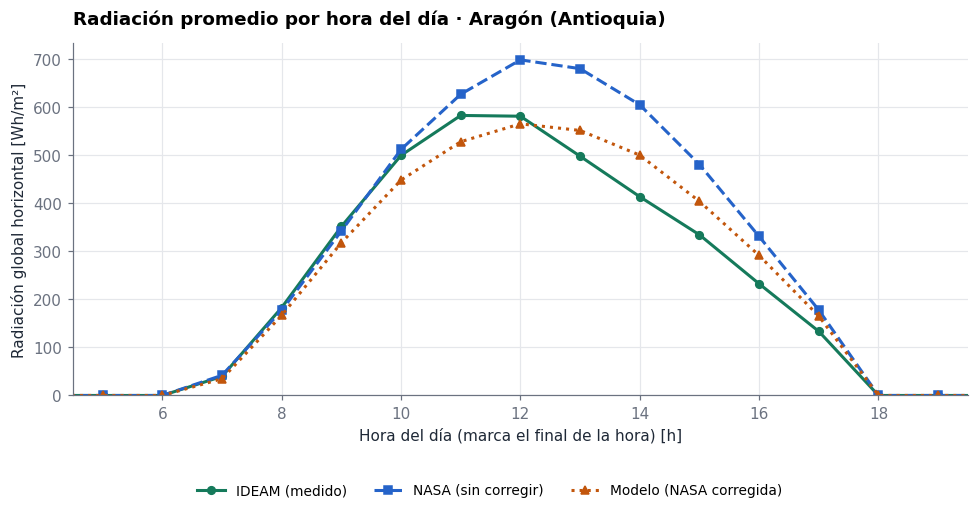

In [26]:
caso_ej = casos[casos.Caso == 'Mayor mejora'].iloc[0]   # el caso del medio
nombre = caso_ej.NombreEstacion
dv = df[df.CodigoEstacion == caso_ej.CodigoEstacion]
anio = r3.anio_tipico(dv)
print('Horas en el año típico:', len(anio))

# Comprobación: las 3 fuentes se promedian sobre las MISMAS horas
conteo = r3.verificar_mismas_horas(dv)
print('Ejemplo, marzo de 12 a 1 p. m.:', conteo.loc[(3, 13)].to_dict())

lugar = nombre_lugar(caso_ej.CodigoEstacion)
dia = anio.groupby('Hora')[list(r3.FUENTES.values())].mean()
fig, ax = plt.subplots(figsize=(9, 4.6))
for f, col in r3.FUENTES.items():
    ax.plot(dia.index, dia[col], color=COLORES[f], label=ETIQ[f], **LINEA[f])
ax.set_title(f'Radiación promedio por hora del día · {lugar}')
ax.set_xlabel('Hora del día (marca el final de la hora) [h]')
ax.set_ylabel('Radiación global horizontal [Wh/m²]')
ax.set_xticks(range(0, 24, 2)); ax.set_xlim(4.5, 19.5); ax.set_ylim(bottom=0)
terminar(fig, 'paso4_radiacion_por_hora')

## Paso 5 · Motor solar: ¿cuánta energía produce el panel?
Para cada hora, `pvlib` hace esto (decisión D13):
1. **Dónde está el sol** a la mitad de la hora (por eso se restan 30 minutos).
2. **Separa** la luz directa de la difusa (fórmula de Erbs).
3. Calcula cuánta luz le llega a un panel **inclinado 10° mirando al sur**.
4. Estima la **temperatura del panel** (fórmula NOCT): con calor rinde menos.
5. Resta **pérdidas** (14 %) y el **inversor** (96 %).

Prueba de sentido común: en Colombia un sistema produce más o menos **1,100–1,500 kWh por cada kWp al año**.

IDEAM  :    1692 kWh/año  →    1128 kWh por kWp   | noche = 0.0
NASA   :    2035 kWh/año  →    1357 kWh por kWp   | noche = 0.0
MODELO :    1741 kWh/año  →    1161 kWh por kWp   | noche = 0.0


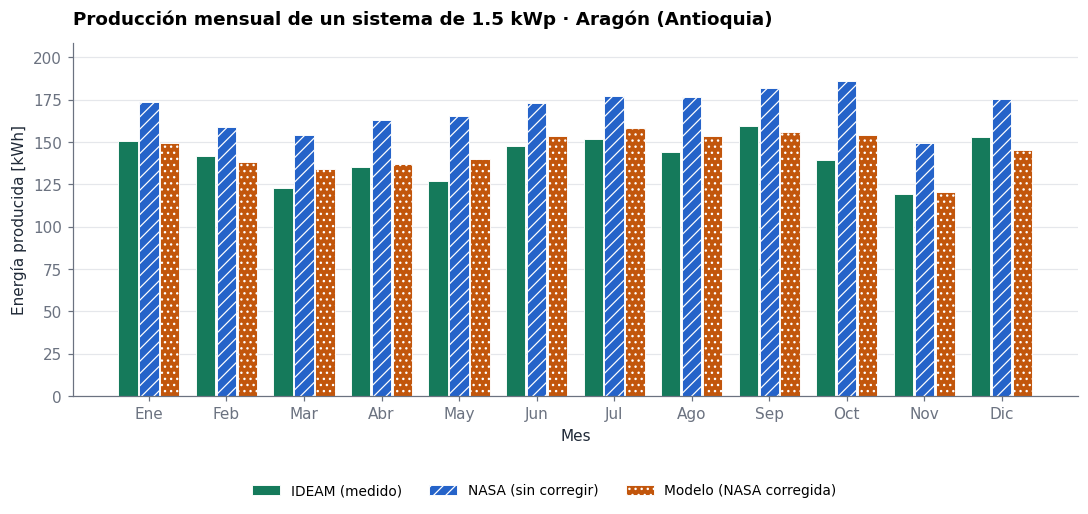

In [27]:
info = dv.iloc[0][['Latitud','Longitud','Altitud']].to_dict()
kwp = r3.v(cfg['sistema']['kWp'])
prod = {f: r3.produccion_panel(anio[col], anio['T2M'], anio['Fecha'], info['Latitud'], info['Longitud'], info['Altitud'], cfg)
        for f, col in r3.FUENTES.items()}
for f, p in prod.items():
    print(f'{f:7s}: {p.sum():7.0f} kWh/año  →  {p.sum()/kwp:6.0f} kWh por kWp   | noche = {p[anio.Valor==0].max():.1f}')

mes = pd.DataFrame({f: pd.Series(p).groupby(anio.Mes.values).sum() for f, p in prod.items()})
fig, ax = plt.subplots(figsize=(10, 4.6))
x, w = np.arange(12), 0.27
for k, f in enumerate(mes.columns):
    ax.bar(x + (k - 1) * w, mes[f], w * 0.92, color=COLORES[f], hatch=TRAMA[f],
           edgecolor='white', linewidth=0.6, label=ETIQ[f])
ax.set_xticks(x); ax.set_xticklabels(MESES)
ax.set_title(f'Producción mensual de un sistema de {kwp} kWp · {lugar}')
ax.set_xlabel('Mes'); ax.set_ylabel('Energía producida [kWh]')
ax.set_ylim(0, mes.values.max() * 1.12); ax.grid(axis='x', visible=False)
terminar(fig, 'paso5_produccion_mensual')

## Paso 6 · Consumo de la casa y balance hora a hora
La casa gasta su consumo mensual (157 kWh, promedio UPME) repartido en el día con una **forma** distinta entre semana y fin de semana (D15).

Comparando hora por hora:
- **Autoconsumo** = lo que la casa usa directo del panel → ahorra a tarifa completa.
- **Excedente** = lo que sobra y se va a la red → se paga más barato (CREG 174).

Fíjate en la gráfica: el panel produce al **mediodía**, pero la casa gasta más en la **noche**. Por eso mucho se vuelve excedente.

✅ Comprobación del plan (R3-3): **autoconsumo + excedente = producción**.

Producción   : 1741 kWh/año
Consumo casa : 1884 kWh/año
Autoconsumo  : 680 | Excedente: 1061
¿Cuadra? -> True


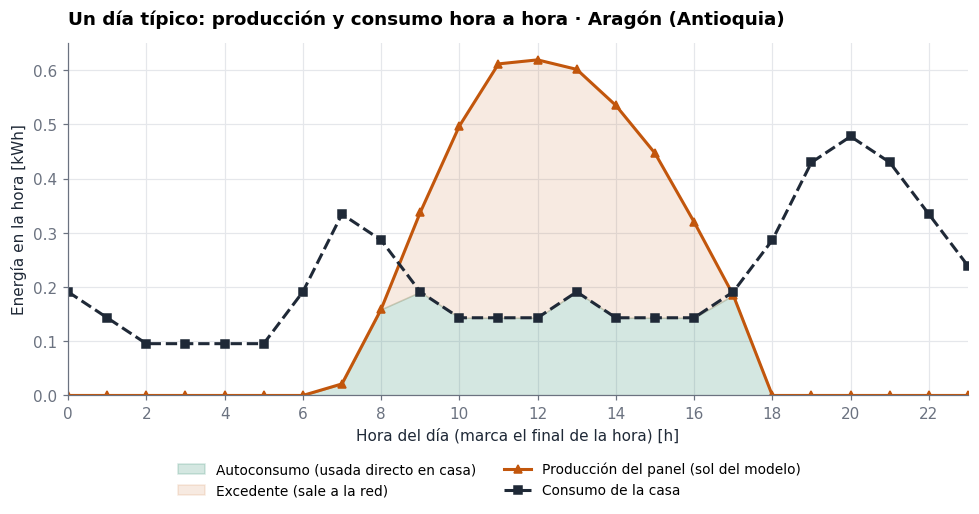

In [28]:
cons = r3.consumo_hogar(anio['Fecha'], cfg)
h = r3.balance(prod['MODELO'], cons, anio['Fecha'])
# h = r3.balance(prod['IDEAM'],  cons, anio['Fecha'])   # con el sol medido
print('Producción   :', round(h['prod'].sum()), 'kWh/año')
print('Consumo casa :', round(h['cons'].sum()), 'kWh/año')
print('Autoconsumo  :', round(h['auto'].sum()), '| Excedente:', round(h['exced'].sum()))
print('¿Cuadra? ->', np.isclose(h['auto'].sum() + h['exced'].sum(), h['prod'].sum()))

d = h[h.Fecha.dt.date == pd.Timestamp('2021-03-10').date()]   # un miércoles cualquiera del año típico
hh = d.Fecha.dt.hour
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.fill_between(hh, d['auto'], color=COLORES['IDEAM'], alpha=0.18, step=None, label='Autoconsumo (usada directo en casa)')
ax.fill_between(hh, d['auto'], d['prod'], color=COLORES['MODELO'], alpha=0.12, label='Excedente (sale a la red)')
ax.plot(hh, d['prod'], color=COLORES['MODELO'], marker='^', label='Producción del panel (sol del modelo)')
ax.plot(hh, d['cons'], color=TINTA, ls='--', marker='s', label='Consumo de la casa')
ax.set_title(f'Un día típico: producción y consumo hora a hora · {lugar}')
ax.set_xlabel('Hora del día (marca el final de la hora) [h]'); ax.set_ylabel('Energía en la hora [kWh]')
ax.set_xticks(range(0, 25, 2)); ax.set_xlim(0, 23); ax.set_ylim(bottom=0)
terminar(fig, 'paso6_dia_tipico', ncol=2)

## Paso 7 · Pasar a plata: ahorro, VPN y Payback
- **Ahorro año 1** = lo que la familia pagaría a EPM **sin** paneles menos lo que paga **con** paneles.
  - EPM cobra los primeros kWh del mes (consumo de subsistencia: 173 kWh bajo 1,000 m de altura, 130 kWh desde 1,000 m) a tarifa de subsistencia y el resto a tarifa plena.
  - El excedente hasta lo que la casa compró en el mes se descuenta kWh por kWh, pero EPM cobra el cargo de comercialización ($114.28/kWh).
  - El excedente que sobra se le paga a la familia (precio de bolsa / MC).
- **Payback simple** = años hasta que el ahorro acumulado paga la inversión.
- **Payback descontado** = igual, pero un peso futuro vale menos que uno de hoy (tasa de descuento).
- **VPN** = cuánto vale *hoy* todo el negocio. Si es positivo, conviene.
- Se incluyen: mantenimiento anual, degradación del panel y cambio del inversor.

In [29]:
a = r3.ahorro_anual(h, cfg, cfg['consumo']['estrato'], info['Altitud'])
fin = r3.finanzas(a, cfg, kwp)
pd.Series({**a, **fin}).round(2).to_frame(f'{nombre} · MODELO')

,ARAGÓN - AUT · MODELO
kWh_produccion,1741.11
kWh_consumo,1884.00
kWh_autoconsumo,680.03
kWh_excedente,1061.08
kWh_credito_energia,1059.76
kWh_excedente_vendido,1.32
consumo_subsistencia_kwh_mes,130.00
factura_anual_sin_panel_cop,1635618.36
ahorro_autoconsumo_cop,621163.36
valor_credito_energia_cop,771831.50


## Paso 8 · ⭐ El resultado principal: 3 lugares × 3 fuentes
Mismos supuestos para todos; **solo cambia de dónde sale el sol**. La columna clave es `dif_payback_simple_anios_vs_IDEAM`: cuántos años se equivoca el Payback frente al calculado con la medición real.
- Si NASA se equivoca más que el MODELO → el modelo le sirve a la familia.
- Si en algún lugar el MODELO se equivoca más → se reporta con honestidad (lugar donde no supera a NASA).

In [30]:
res = r3.correr_casos(df, casos, cfg)
cols = ['Caso','Fuente','kWh_produccion','kWh_por_kWp','ahorro_anio1_cop','payback_simple_anios','VPN_cop','TIR','dif_payback_simple_anios_vs_IDEAM']
res[cols].round(2)

,Caso,Fuente,kWh_produccion,kWh_por_kWp,ahorro_anio1_cop,payback_simple_anios,VPN_cop,TIR,dif_payback_simple_anios_vs_IDEAM
0,Mayor mejora,IDEAM,1691.58,1127.72,1342454.25,6.05,4032952.01,0.16,0.00
1,Mayor mejora,NASA,2034.81,1356.54,1529150.63,5.26,5810716.67,0.18,-0.79
2,Mayor mejora,MODELO,1741.11,1160.74,1379498.34,5.88,4385694.14,0.16,-0.18
3,Mediana,IDEAM,1830.06,1220.04,1432264.29,5.64,4888143.30,0.17,0.00
4,Mediana,NASA,1923.12,1282.08,1482283.10,5.44,5364433.65,0.18,-0.21
5,Mediana,MODELO,1793.83,1195.89,1406065.65,5.76,4638673.99,0.16,0.11
6,Menor mejora,IDEAM,1941.21,1294.14,1480626.49,5.45,5348658.98,0.18,0.00
7,Menor mejora,NASA,1891.42,1260.95,1470222.41,5.49,5249589.01,0.17,0.04
8,Menor mejora,MODELO,1604.85,1069.90,1280509.33,6.37,3443098.72,0.15,0.93


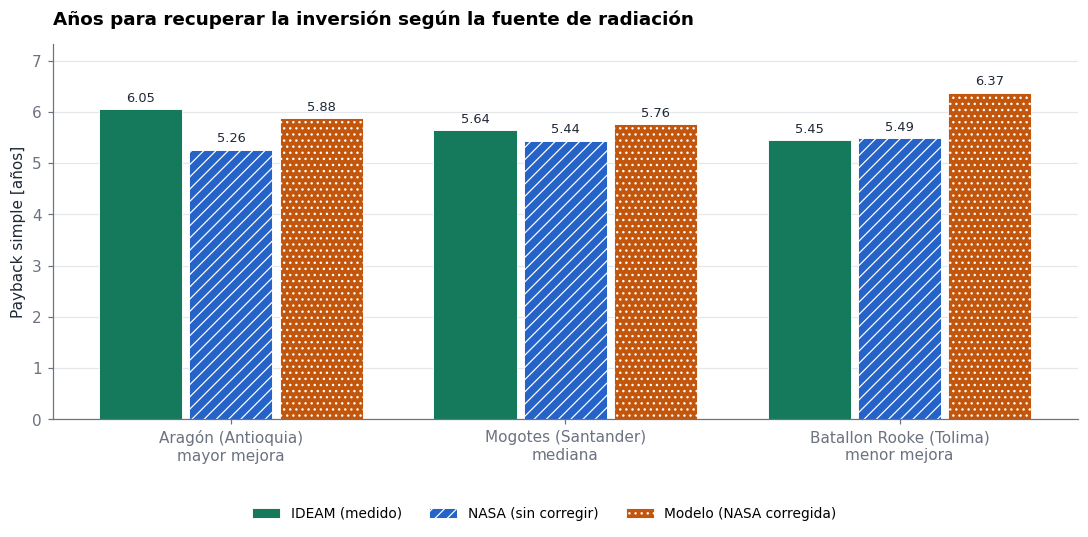

Fuente,IDEAM,NASA,MODELO
Caso,,,
Mayor mejora,6.05,5.26,5.88
Mediana,5.64,5.44,5.76
Menor mejora,5.45,5.49,6.37


In [31]:
orden = ['Mayor mejora', 'Mediana', 'Menor mejora']
codigos = casos.set_index('Caso').loc[orden, 'CodigoEstacion']
t = res.pivot(index='Caso', columns='Fuente', values='payback_simple_anios').loc[orden, ['IDEAM','NASA','MODELO']]
fig, ax = plt.subplots(figsize=(10, 4.8))
x, w = np.arange(len(t)), 0.27
for k, f in enumerate(t.columns):
    b = ax.bar(x + (k - 1) * w, t[f], w * 0.92, color=COLORES[f], hatch=TRAMA[f], edgecolor='white', linewidth=0.6, label=ETIQ[f])
    ax.bar_label(b, fmt='%.2f', padding=3, fontsize=8.5, color=TINTA)
ax.set_xticks(x); ax.set_xticklabels([f'{nombre_lugar(c)}\n{caso.lower()}' for caso, c in codigos.items()])
ax.set_title('Años para recuperar la inversión según la fuente de radiación')
ax.set_ylabel('Payback simple [años]'); ax.set_ylim(0, t.values.max() * 1.15); ax.grid(axis='x', visible=False)
terminar(fig, 'paso8_payback_por_fuente')
t.round(2)

**¿Cuánto se equivoca cada fuente?** La barra mide la diferencia con el Payback del IDEAM (la realidad). Entre más corta, mejor. Hacia la izquierda: la fuente promete recuperar la plata **antes** de lo real; hacia la derecha: **después**.

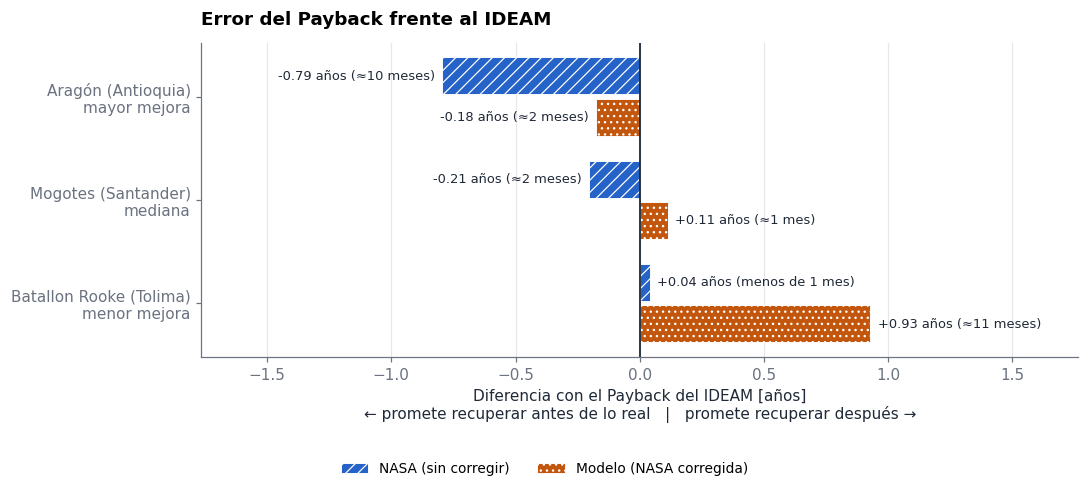

In [32]:
err = res[res.Fuente != 'IDEAM'].pivot(index='Caso', columns='Fuente', values='dif_payback_simple_anios_vs_IDEAM').loc[orden, ['NASA','MODELO']]
fig, ax = plt.subplots(figsize=(10, 4.4))
y, h = np.arange(len(err)), 0.36
for k, f in enumerate(err.columns):
    yy = y + (k - 0.5) * (h + 0.04)
    ax.barh(yy, err[f], h, color=COLORES[f], hatch=TRAMA[f], edgecolor='white', linewidth=0.6, label=ETIQ[f])
    for yi, vv in zip(yy, err[f]):
        meses = round(abs(vv) * 12)
        txt = 'menos de 1 mes' if meses < 1 else ('≈1 mes' if meses == 1 else f'≈{meses} meses')
        ax.text(vv + (0.03 if vv >= 0 else -0.03), yi, f'{vv:+.2f} años ({txt})', va='center',
                ha='left' if vv >= 0 else 'right', fontsize=8.5, color=TINTA)
ax.axvline(0, color=TINTA, lw=1.2)
ax.set_yticks(y); ax.set_yticklabels([f'{nombre_lugar(c)}\n{caso.lower()}' for caso, c in codigos.items()]); ax.invert_yaxis()
lim = max(1.0, err.abs().values.max() * 1.9); ax.set_xlim(-lim, lim)
ax.set_title('Error del Payback frente al IDEAM'); ax.grid(axis='y', visible=False)
ax.set_xlabel('Diferencia con el Payback del IDEAM [años]\n← promete recuperar antes de lo real   |   promete recuperar después →')
terminar(fig, 'paso8_error_payback', ncol=2)

## Paso 9 · Sensibilidad: mover una perilla a la vez
Respondemos preguntas como *"¿qué pasa con el Payback si el costo sube 20 %?"*. Se mueve **un solo parámetro** y los demás quedan fijos.

,Parametro,Valor,Payback_base,Payback_nuevo,Cambio_payback_anios
50,costo_por_kWp_cop,3500000.00,5.76,3.93,-1.82
51,costo_por_kWp_cop,7000000.00,5.76,8.34,2.58
52,tarifa_factor,0.80,5.76,7.51,1.75
53,tarifa_factor,1.20,5.76,4.67,-1.09
54,precio_excedente_tramo2_cop,130.00,5.76,5.79,0.03
55,precio_excedente_tramo2_cop,950.00,5.76,5.67,-0.09
56,tasa_descuento,0.06,5.76,5.76,0.00
57,tasa_descuento,0.12,5.76,5.76,0.00
58,kWp,1.00,5.76,5.47,-0.28
59,kWp,2.00,5.76,6.60,0.84


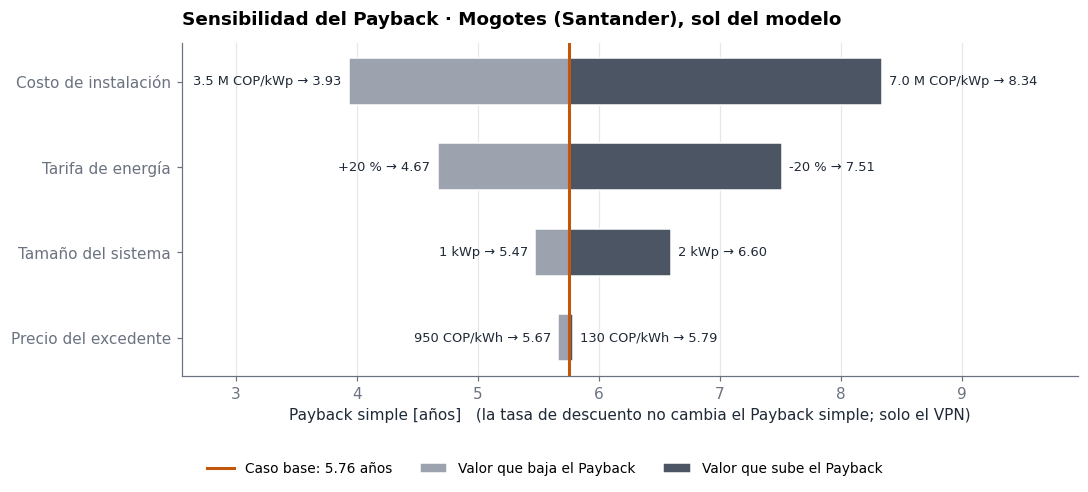

In [33]:
sen = r3.sensibilidad(df, casos, cfg)
s = sen[(sen.Fuente=='MODELO') & (sen.Caso == 'Mediana')]
display(s[['Parametro','Valor','Payback_base','Payback_nuevo','Cambio_payback_anios']].round(2))

# Gráfica de tornado: la barra más larga es lo que más mueve el Payback
nombres = {'costo_por_kWp_cop': 'Costo de instalación', 'tarifa_factor': 'Tarifa de energía',
           'precio_excedente_tramo2_cop': 'Precio del excedente', 'kWp': 'Tamaño del sistema'}
def valor_txt(par, val):
    val = float(val)
    return {'costo_por_kWp_cop': f'{val/1e6:.1f} M COP/kWp', 'tarifa_factor': f'{(val-1)*100:+.0f} %',
            'precio_excedente_tramo2_cop': f'{val:.0f} COP/kWh', 'kWp': f'{val:g} kWp'}.get(par, f'{val:g}')
ss = s[s.Parametro.isin(nombres)]
base = ss.Payback_base.iloc[0]
filas = sorted([(p, g.sort_values('Payback_nuevo')) for p, g in ss.groupby('Parametro')],
               key=lambda t: t[1].Payback_nuevo.max() - t[1].Payback_nuevo.min())
fig, ax = plt.subplots(figsize=(10, 4.4))
for i, (par, g) in enumerate(filas):
    for (_, r), col, lab in zip(g.iterrows(), ['#9CA3AF', '#4B5563'], ['Valor que baja el Payback', 'Valor que sube el Payback']):
        ax.barh(i, r.Payback_nuevo - base, left=base, height=0.55, color=col, edgecolor='white', label=lab if i == 0 else None)
        ax.text(r.Payback_nuevo + (0.06 if r.Payback_nuevo >= base else -0.06), i, f'{valor_txt(par, r.Valor)} → {r.Payback_nuevo:.2f}',
                va='center', ha='left' if r.Payback_nuevo >= base else 'right', fontsize=8.5, color=TINTA)
ax.axvline(base, color=COLORES['MODELO'], lw=2, label=f'Caso base: {base:.2f} años')
ax.set_yticks(range(len(filas))); ax.set_yticklabels([nombres[p] for p, _ in filas]); ax.grid(axis='y', visible=False)
ax.set_xlim(base - 3.2, base + 4.2)
ax.set_title(f'Sensibilidad del Payback · {nombre_lugar(casos.set_index("Caso").loc["Mediana", "CodigoEstacion"])}, sol del modelo')
ax.set_xlabel('Payback simple [años]   (la tasa de descuento no cambia el Payback simple; solo el VPN)')
terminar(fig, 'paso9_sensibilidad', ncol=3)

## Paso 10 · Guardar y entregar a Felipe (R5)
Se guardan en la carpeta `resultados`. Descárgalos (clic derecho → Descargar) o súbelos a la carpeta `resultados` del bucket.

In [34]:
import os; os.makedirs('resultados', exist_ok=True)
res.to_parquet('resultados/r3_resultados_casos.parquet', index=False)
sen.to_parquet('resultados/r3_sensibilidad.parquet', index=False)
mejora.to_parquet('resultados/r3_mejora_por_estacion.parquet', index=False)
r3.ficha_supuestos(cfg).to_csv('resultados/r3_ficha_supuestos.csv', index=False)
res.to_csv('resultados/r3_resultados_casos.csv', index=False)   # para abrir en Excel
os.listdir('resultados')

['r3_punto_por_tamano.csv',
 'r3_mejora_por_estacion.parquet',
 'r3_mis_valores_3_lugares.csv',
 'r3_resultados_casos.csv',
 'r3_resultados_casos.parquet',
 'r3_punto_nuevo.csv',
 'r3_punto_por_estrato.csv',
 'r3_ficha_supuestos.csv',
 'r3_sensibilidad.parquet']

## Paso 10b · ✏️ Prueba TUS valores en los 3 lugares
Aquí puedes cambiar **todo**: estrato, consumo de la casa, tamaño del sistema, costo, inclinación del panel, tarifa, precio del excedente y tasa de descuento. No necesita internet ni archivos extra.

**Cómo se usa:** a la derecha de la celda aparece un formulario. Cambia los números y corre la celda (▶). Los valores que trae son los de la ficha (caso base).

| Campo | Qué es | Valor base |
|---|---|---|
| estrato | Estrato de la casa (1 a 6). Cambia la tarifa de EPM | 3 |
| kwh_mes | Lo que gasta la casa al mes | 157 kWh |
| kwp | Tamaño del sistema de paneles | 1.5 kWp |
| costo_kwp | Lo que cuesta instalar cada kWp | $5,000,000 |
| inclinacion | Inclinación del panel en grados (0 = acostado) | 10° |
| azimut | Hacia dónde mira el panel (180 = sur, 0 = norte, 90 = oriente, 270 = occidente) | 180 |
| factor_tarifa | 1.0 = tarifa de hoy; 1.2 = 20 % más cara; 0.8 = 20 % más barata | 1.0 |
| precio_excedente | Lo que pagan por la energía que sobra (después de cambiarla 1 a 1) | $331/kWh |
| tasa_descuento | Para el VPN y el Payback descontado (0.09 = 9 %) | 0.09 |

In [35]:
#@title ✏️ Tus valores para los 3 lugares (cambia y corre ▶)
estrato          = 3        #@param [1, 2, 3, 4, 5, 6] {type:"raw"}
kwh_mes          = 157      #@param {type:"number"}
kwp              = 1.5      #@param {type:"number"}
costo_kwp        = 5000000  #@param {type:"number"}
inclinacion      = 10       #@param {type:"number"}
azimut           = 180      #@param {type:"number"}
factor_tarifa    = 1.0      #@param {type:"number"}
precio_excedente = 331      #@param {type:"number"}
tasa_descuento   = 0.09     #@param {type:"number"}

mio = r3.correr_casos(df, casos, cfg, inclinacion=inclinacion, azimut=azimut,
                      estrato=int(estrato), kwh_mes=kwh_mes, kwp=kwp, costo_kwp=costo_kwp,
                      f_tarifa=factor_tarifa, precio_exc2=precio_excedente, tasa=tasa_descuento)
mio['estrato'], mio['kWp'] = int(estrato), kwp
display(r3.resumen_legible(mio).set_index(['Lugar', 'Fuente del sol']).T)
mio.to_csv('resultados/r3_mis_valores_3_lugares.csv', index=False)
print('Guardado en resultados/r3_mis_valores_3_lugares.csv')

Lugar                            ARAGÓN - AUT                             MOGOTES - AUT                         BATALLON ROOKE  - AUT                            
Fuente del sol                          IDEAM          NASA        MODELO         IDEAM        NASA      MODELO                 IDEAM          NASA        MODELO
Caso                             Mayor mejora  Mayor mejora  Mayor mejora       Mediana     Mediana     Mediana          Menor mejora  Menor mejora  Menor mejora
Estrato                                     3             3             3             3           3           3                     3             3             3
Tamaño (kWp)                              1.5           1.5           1.5           1.5         1.5         1.5                   1.5           1.5           1.5
Altura (m)                               2633          2633          2633          1673        1673        1673                  1285          1285          1285
Energía producida (kWh/año)           1691.58       2034.81       1741.11       1830.06     1923.12     1793.83               1941.21       1891.42       1604.85
Consumo casa (kWh/año)                 1884.0        1884.0        1884.0        1884.0      1884.0      1884.0                1884.0        1884.0        1884.0
Usada directo en casa (kWh/año)        679.14        689.69        680.03        677.58      706.48      692.71                 686.1        685.28        668.83
Sobra a la red (kWh/año)              1012.44       1345.12       1061.08       1152.49     1216.64     1101.12               1255.11       1206.14        936.03
Factura sin paneles ($/año)        1635618.36    1635618.36    1635618.36    1635618.36  1635618.36  1635618.36            1635618.36    1635618.36    1635618.36
Ahorro año 1 ($)                   1342454.25    1529150.63    1379498.34    1432264.29   1482283.1  1406065.65            1480626.49    1470222.41    1280509.33
Inversión ($)                       7500000.0     7500000.0     7500000.0     7500000.0   7500000.0   7500000.0             7500000.0     7500000.0     7500000.0
Payback simple (años)                    6.05          5.26          5.88          5.64        5.44        5.76                  5.45          5.49          6.37
Payback descontado (años)                 9.2          7.48          8.79          8.28        7.84        8.53                  7.86          7.94          9.97
VPN ($)                            4032952.01    5810716.67    4385694.14     4888143.3  5364433.65  4638673.99            5348658.98    5249589.01    3443098.72
TIR                                    15.5 %        18.2 %        16.1 %        16.8 %      17.6 %      16.5 %                17.5 %        17.4 %        14.6 %
CO2 evitado (t/año)                      1.12          1.34          1.15          1.21        1.27        1.18                  1.28          1.25          1.06
kWh por kWp al año                    1127.72       1356.54       1160.74       1220.04     1282.08     1195.89               1294.14       1260.95        1069.9

Guardado en resultados/r3_mis_valores_3_lugares.csv


## Paso 11 · Calcular CUALQUIER lugar de Colombia (sin estación del IDEAM)
Este es el flujo que usaría la página web:
1. **Se descargan de NASA** los datos de ese punto (sol, sol despejado, nubosidad, temperatura y altura), hora por hora.
2. **El modelo** (`modelo_lgbm.joblib`) los corrige.
3. **Tu motor** calcula energía, ahorro, Payback, VPN y TIR.

Aquí no hay IDEAM, porque no hay estación: el resultado que se usaría es el del **MODELO**; el de **NASA** sale solo como referencia.

⚠️ **Para este paso necesitas:**
- **Internet** (Colab lo tiene).
- Subir también `modelo_lgbm.joblib` (siempre) y `gold_v1_unico.parquet` (solo para la comprobación 11.1).

### 11.0 · ¿Están los archivos?

In [36]:
import os
for f in [cfg['datos']['modelo'], cfg['datos']['tabla_gold']]:
    print(f, '→', '✅ está' if os.path.exists(f) else '❌ falta: súbelo en la carpeta de la izquierda')

modelo_lgbm.joblib → ✅ está
gold_v1_unico.parquet → ✅ está


### 11.1 · Comprobación de horas (hacerla UNA vez)
Descarga NASA en la estación de Villeta (23065180), que está en la tabla gold con datos de 2021, y compara. **El desfase de la primera fila** es el que hace coincidir la descarga con la tabla del equipo; su diferencia debería ser casi 0.
- Si el desfase es **0**, no hay que cambiar nada.
- Si es otro número (por ejemplo **1**), escríbelo en `config_r3.yaml`, en `desfase_nasa_horas:`, guarda, vuelve a subir el archivo y vuelve a correr el Paso 1.
- Si no subiste el `.parquet`, esta celda se salta sola.

In [37]:
# NECESITA INTERNET y gold_v1_unico.parquet
if os.path.exists(cfg['datos']['tabla_gold']):
    tabla = r3.cargar_tabla(cfg, [23065180])   # estación de Villeta en la tabla gold
    cal = r3.calibrar_desfase_nasa(tabla, 23065180, 2021, cfg)
    display(cal)
else:
    print('Se salta: no está gold_v1_unico.parquet (solo hace falta para esta comprobación).')

,desfase_horas,horas_comparadas,diferencia_promedio_Wh_m2
0,0,4345,0.000010
1,1,3991,134.411781
2,-1,3982,134.549347
3,2,3628,257.590612
4,-2,3619,257.904477
5,3,3264,358.274292
6,-3,3256,358.509101


### 11.2 · ✏️ Calcular un lugar con TUS valores
Escribe las **coordenadas** del lugar (en Google Maps: clic derecho sobre el punto → aparecen los dos números; el primero es la latitud y el segundo la longitud) y los demás valores, y corre la celda (▶).

- La **altura** no se escribe: la da NASA para ese punto, y con ella se escoge el consumo de subsistencia (173 o 130 kWh).
- `anios_nasa` son los años que se descargan para armar el año típico.
- Los campos son los mismos del Paso 10b.

In [38]:
#@title ✏️ Lugar nuevo y tus valores (cambia y corre ▶)
latitud          = 2.19     #@param {type:"number"}
longitud         = -75.63   #@param {type:"number"}
anios_nasa       = "2023, 2024, 2025"  #@param {type:"string"}
estrato          = 3        #@param [1, 2, 3, 4, 5, 6] {type:"raw"}
kwh_mes          = 157      #@param {type:"number"}
kwp              = 1.5      #@param {type:"number"}
costo_kwp        = 5000000  #@param {type:"number"}
inclinacion      = 10       #@param {type:"number"}
azimut           = 180      #@param {type:"number"}
factor_tarifa    = 1.0      #@param {type:"number"}
precio_excedente = 331      #@param {type:"number"}
tasa_descuento   = 0.09     #@param {type:"number"}

# NECESITA INTERNET y modelo_lgbm.joblib
anios = [int(a) for a in anios_nasa.replace(' ', '').split(',') if a]
datos_punto = r3.descargar_nasa_punto(latitud, longitud, anios, cfg)   # se descarga UNA vez
print(f'Descargadas {len(datos_punto):,} horas con sol · altura según NASA: {datos_punto.Altitud.iloc[0]:.0f} m')

valores = dict(estrato=int(estrato), kwh_mes=kwh_mes, kwp=kwp, costo_kwp=costo_kwp, inclinacion=inclinacion,
               azimut=azimut, f_tarifa=factor_tarifa, precio_exc2=precio_excedente, tasa=tasa_descuento)
punto = r3.calcular_punto(latitud, longitud, cfg, datos_nasa=datos_punto, **valores)
display(r3.resumen_legible(punto).set_index('Fuente del sol').T)

m = punto[punto.Fuente == 'MODELO'].iloc[0]
print(f"""
En palabras (con el sol del MODELO):
 · El sistema de {kwp} kWp produce {m.kWh_produccion:,.0f} kWh al año.
 · La familia ahorra ${m.ahorro_anio1_cop:,.0f} el primer año.
 · Recupera la inversión de ${m.capex_cop:,.0f} en {m.payback_simple_anios:.1f} años ({m.payback_descontado_anios:.1f} contando que la plata futura vale menos).
 · VPN: ${m.VPN_cop:,.0f} → {'CONVIENE' if m.VPN_cop > 0 else 'NO conviene'} · TIR: {m.TIR*100:.1f} % (frente al {tasa_descuento*100:.0f} % de referencia)
 · Evita {m.co2_evitado_t_anio:.2f} toneladas de CO2 al año.""")
os.makedirs('resultados', exist_ok=True)
punto.to_csv('resultados/r3_punto_nuevo.csv', index=False)

Descargadas 13,152 horas con sol · altura según NASA: 1411 m


Fuente del sol,MODELO,NASA
Estrato,3,3
Tamaño (kWp),1.5,1.5
Altura (m),1411.01,1411.01
Energía producida (kWh/año),1852.43,1845.82
Consumo casa (kWh/año),1884.0,1884.0
Usada directo en casa (kWh/año),715.95,702.91
Sobra a la red (kWh/año),1136.48,1142.91
Factura sin paneles ($/año),1635618.36,1635618.36
Ahorro año 1 ($),1444674.29,1441381.96
Inversión ($),7500000.0,7500000.0



En palabras (con el sol del MODELO):
 · El sistema de 1.5 kWp produce 1,852 kWh al año.
 · La familia ahorra $1,444,674 el primer año.
 · Recupera la inversión de $7,500,000 en 5.6 años (8.2 contando que la plata futura vale menos).
 · VPN: $5,006,314 → CONVIENE · TIR: 17.0 % (frente al 9 % de referencia)
 · Evita 1.22 toneladas de CO2 al año.


### 11.3 · Mismo lugar, todos los estratos y varios tamaños
Usa los datos que ya se descargaron en 11.2 (no vuelve a descargar). Sirve para responder: *"¿y si la casa fuera estrato 1? ¿y si pone 3 kWp?"*. Sale con el sol del **MODELO** y los demás valores de 11.2.

,Factura sin paneles ($/año),Ahorro año 1 ($),Payback simple (años),Payback descontado (años),VPN ($),TIR
Estrato,,,,,,
1,987360.36,836463.00,10.26,no se recupera en 25 años,-785209.73,7.6 %
2,1153921.56,992734.73,8.45,19.09,702844.67,10.2 %
3,1635618.36,1444674.29,5.59,8.16,5006314.15,17.0 %
4,1867590.36,1662316.02,4.81,6.61,7078747.31,20.1 %
5,2241093.36,2016071.27,3.92,5.06,10447283.82,25.0 %
6,2241093.36,2016071.27,3.92,5.06,10447283.82,25.0 %


,Inversión ($),Energía producida (kWh/año),Sobra a la red (kWh/año),Ahorro año 1 ($),Payback simple (años),VPN ($),TIR
Tamaño (kWp),,,,,,,
1.0,5000000.0,1234.95,576.97,1012571.25,5.30,3686409.78,17.9 %
1.5,7500000.0,1852.43,1136.48,1444674.29,5.59,5006314.15,17.0 %
2.0,10000000.0,2469.90,1719.31,1683025.33,6.47,4481268.58,14.5 %
3.0,15000000.0,3704.85,2910.73,2092631.21,7.96,2792272.49,11.3 %
5.0,25000000.0,6174.75,5330.91,2907618.37,9.78,-625947.24,8.7 %


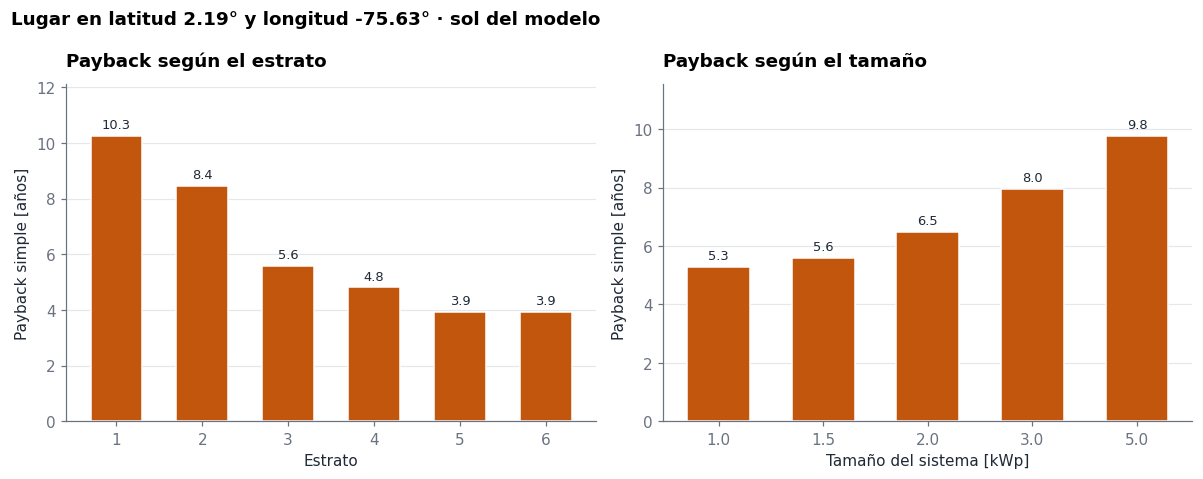

In [39]:
filas = []
for e in [1, 2, 3, 4, 5, 6]:
    p = r3.calcular_punto(latitud, longitud, cfg, datos_nasa=datos_punto, **{**valores, 'estrato': e})
    filas.append(p[p.Fuente == 'MODELO'])
por_estrato = pd.concat(filas)
display(r3.resumen_legible(por_estrato).set_index('Estrato')[['Factura sin paneles ($/año)', 'Ahorro año 1 ($)',
        'Payback simple (años)', 'Payback descontado (años)', 'VPN ($)', 'TIR']])

filas = []
for tam in [1.0, 1.5, 2.0, 3.0, 5.0]:
    p = r3.calcular_punto(latitud, longitud, cfg, datos_nasa=datos_punto, **{**valores, 'kwp': tam})
    filas.append(p[p.Fuente == 'MODELO'])
por_tamano = pd.concat(filas)
display(r3.resumen_legible(por_tamano).set_index('Tamaño (kWp)')[['Inversión ($)', 'Energía producida (kWh/año)',
        'Sobra a la red (kWh/año)', 'Ahorro año 1 ($)', 'Payback simple (años)', 'VPN ($)', 'TIR']])
por_estrato.to_csv('resultados/r3_punto_por_estrato.csv', index=False)
por_tamano.to_csv('resultados/r3_punto_por_tamano.csv', index=False)

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, tabla, xcol, xlab in [(axs[0], por_estrato, 'estrato', 'Estrato'), (axs[1], por_tamano, 'kWp', 'Tamaño del sistema [kWp]')]:
    b = ax.bar(tabla[xcol].astype(str), tabla.payback_simple_anios, 0.6, color=COLORES['MODELO'], edgecolor='white')
    ax.bar_label(b, labels=[f'{v:.1f}' if np.isfinite(v) else '>25' for v in tabla.payback_simple_anios], padding=3, fontsize=8.5, color=TINTA)
    ax.set_xlabel(xlab); ax.set_ylabel('Payback simple [años]'); ax.grid(axis='x', visible=False)
    ax.set_ylim(0, np.nanmax(tabla.payback_simple_anios) * 1.18)
axs[0].set_title('Payback según el estrato'); axs[1].set_title('Payback según el tamaño')
fig.suptitle(f'Lugar en latitud {latitud:.2f}° y longitud {longitud:.2f}° · sol del modelo', x=0.01, ha='left', fontweight='bold')
terminar(fig, 'paso11_estratos_y_tamanos', handles=[])

## Si llega una versión nueva de los datos o del modelo
Solo cambias las rutas del **Paso 1** y vuelves a correr todo:
1. `tabla_gold` → el parquet nuevo de Felipe (R5).
2. `modelo` → el modelo nuevo de R1. Si ese modelo predice el valor directo (no la diferencia con NASA), cambia en `config_r3.yaml` la línea `modelo_predice:` a `radiacion`.
3. `casos_r2` → el Excel nuevo de Manuela (R2). El código lee la hoja `mejora_por_sitio` (columna `caso_sugerido`) y la hoja `serie_horaria`.
4. El **Paso 3** muestra el error de cada fuente para revisar que todo tenga sentido.